# Rate My Recipe · Five-Minute Project Presentation

**Can a recipe with one five-star rating really outrank a recipe liked by hundreds of users?**

**Goal:** Rank Food.com recipes using both average star ratings and the number of ratings, then compare the result with a naive average-rating baseline.

**Presentation path (approximately five minutes):**
1. The data and the ranking problem.
2. The two scoring rules.
3. What changes in the top recipes.
4. How smoothing strength affects those choices.
5. Limitations and takeaways.

This notebook reads `data/processed/recipe_rating_summary.csv` produced by `data_exploration.ipynb`. It imports the same tested Python classes used in the detailed analysis. It can run **without running the analysis notebook** and does not write files. **Code cells are folded for presentation; expand them to inspect the implementation.**

## 1. Presentation setup

Imports and compact display helpers are separated from the findings below so the five-minute narrative stays focused.

### 1.1 Imports

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

# This presentation can run without executing the analysis notebook first.
notebook_directory = Path.cwd().resolve()
PROJECT_ROOT = (
    notebook_directory.parent
    if notebook_directory.name == "notebooks"
    else notebook_directory
)
if not (PROJECT_ROOT / "rate_my_recipe").is_dir():
    raise FileNotFoundError("Open Jupyter from the repository root or notebooks/ directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from rate_my_recipe.evaluation import RankingEvaluator
from rate_my_recipe.ranking import RecipeRanker

### 1.2 Table-formatting helper

Only display formatting belongs here; all statistical calculations remain in the production modules.

In [2]:
def presentation_leaderboard(
    ranking: pd.DataFrame,
    method: str,
    top_k: int = 5,
) -> pd.DataFrame:
    """Return a short leaderboard suitable for a presentation slide."""
    selected_columns = [
        "rank", "recipe_name", "valid_rating_count", "ranking_score",
    ]
    return (
        ranking.loc[:, selected_columns]
        .head(top_k)
        .assign(method=method)
        .round({"ranking_score": 3})
        [["method", *selected_columns]]
    )

### 1.3 Input and presentation parameters

In [3]:
RATING_SUMMARY_CSV = PROJECT_ROOT / "data" / "processed" / "recipe_rating_summary.csv"
SMOOTHING_STRENGTH = 10.0
PRESENTATION_TOP_K = 20

if not RATING_SUMMARY_CSV.is_file():
    raise FileNotFoundError(
        "Missing data/processed/recipe_rating_summary.csv. Run data_exploration.ipynb first."
    )

sns.set_theme(style="whitegrid", context="notebook")

### 1.4 Load prepared recipe data

In [4]:
recipe_rating_summary = pd.read_csv(RATING_SUMMARY_CSV)
print(f"Loaded {len(recipe_rating_summary):,} recipes.")

Loaded 231,637 recipes.


## 2. The data: many recipes, uneven evidence

Food.com provides recipe metadata plus user interactions. Ratings from **1 to 5** are valid stars. A recorded **0** counts as an interaction but not as a star rating. Recipes without valid stars remain in the data but cannot enter a rating-based leaderboard.

### 2.1 Summarize the ranking population

In [5]:
recipe_ranker = RecipeRanker(recipe_rating_summary)

population_summary = pd.Series({
    "total_recipes": len(recipe_rating_summary),
    "rated_recipes": int(recipe_rating_summary["valid_rating_count"].gt(0).sum()),
    "unrated_recipes": int(recipe_rating_summary["valid_rating_count"].eq(0).sum()),
    "total_valid_star_ratings": int(recipe_rating_summary["valid_rating_count"].sum()),
    "global_valid_star_mean": recipe_ranker.calculate_global_mean_rating(),
}, name="value")

In [6]:
formatted_population_summary = population_summary.map(
    lambda value: f"{value:,.0f}"
)
formatted_population_summary["global_valid_star_mean"] = (
    f"{population_summary['global_valid_star_mean']:.4f}"
)

display(formatted_population_summary.to_frame(name="value"))

,value
total_recipes,"231,637"
rated_recipes,"226,590"
unrated_recipes,"5,047"
total_valid_star_ratings,"1,071,520"
global_valid_star_mean,4.6615


## 3. The method: average alone versus count-aware scoring

The **naive score** is the average star rating \(\bar r_i\).

The **weighted score** incorporates the number \(n_i\) of valid ratings:

\[
\boxed{\displaystyle S_i = \frac{n_i\bar r_i + mC}{n_i + m}}
\]

Here, \(C\) is the dataset-wide mean of individual valid ratings, and \(m=10\) is the chosen smoothing strength. Few ratings imply stronger shrinkage toward \(C\); many ratings give greater influence to the observed recipe mean.

**Model choice:** We compare this approach against a mean-rating baseline. The Wilson lower bound is built for binary outcomes and is not applied directly to these 1–5-star ratings.

### 3.1 Generate both leaderboards

In [7]:
naive_ranking = recipe_ranker.rank_by_mean_rating()
weighted_ranking = recipe_ranker.rank_by_bayesian_score(SMOOTHING_STRENGTH)
ranking_evaluator = RankingEvaluator(naive_ranking, weighted_ranking)
print(f"Ranked recipes: {len(naive_ranking):,}")

Ranked recipes: 226,590


### 3.2 Compare the top five

Notice that two scoring methods can select different recipes, even when all scores are on the same 1–5 scale.

In [8]:
top_five_comparison = pd.concat([
    presentation_leaderboard(naive_ranking, "Naive mean"),
    presentation_leaderboard(weighted_ranking, "Weighted score"),
], ignore_index=True)
display(top_five_comparison)

,method,rank,recipe_name,valid_rating_count,ranking_score
0,Naive mean,1,bacon lattice tomato muffins rsc,192,5.000
1,Naive mean,2,company s coming mashed potatoes,95,5.000
2,Naive mean,3,simply irresistible tropical potato salad sp5,73,5.000
3,Naive mean,4,kittencal s balsamic vinaigrette,69,5.000
4,Naive mean,5,the best creole cajun seasoning mix,67,5.000
5,Weighted score,1,bacon lattice tomato muffins rsc,192,4.983
6,Weighted score,2,mexican stack up rsc,217,4.976
7,Weighted score,3,company s coming mashed potatoes,95,4.968
8,Weighted score,4,simply irresistible tropical potato salad sp5,73,4.959
9,Weighted score,5,kittencal s balsamic vinaigrette,69,4.957


## 4. Finding 1: the top lists change

We measure the percentage of shared recipes across different top-k cutoffs. An overlap of 50% at \(k=20\), for example, means that only 10 recipes occur in both top-20 lists.

### 4.1 Calculate leaderboard overlap

In [9]:
top_k_overlap = pd.DataFrame([
    ranking_evaluator.compare_top_k(top_k=k)
    for k in [10, 20, 50, 100]
])
display(top_k_overlap)

,top_k,shared_recipe_count,overlap_percentage
0,10,6,60.0
1,20,10,50.0
2,50,29,58.0
3,100,46,46.0


### 4.2 Visualize how agreement changes with k

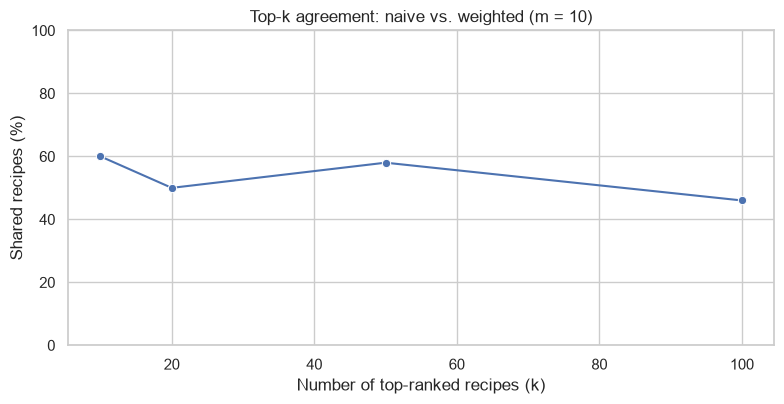

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.lineplot(data=top_k_overlap, x="top_k", y="overlap_percentage", marker="o", ax=ax)
ax.set(
    title=f"Top-k agreement: naive vs. weighted (m = {SMOOTHING_STRENGTH:g})",
    xlabel="Number of top-ranked recipes (k)",
    ylabel="Shared recipes (%)",
    ylim=(0, 100),
)
plt.tight_layout()
plt.show()

## 5. Finding 2: higher-ranked recipes tend to have more rating evidence

We compare **valid-rating counts**, not interaction counts. A larger count reflects more feedback supporting the score, but it is **not itself proof of higher recipe quality**.

### 5.1 Compare top-20 rating-count medians

In [11]:
top_20_rating_evidence = ranking_evaluator.compare_top_k_rating_counts(
    top_k=PRESENTATION_TOP_K
)
display(top_20_rating_evidence[[
    "ranking_method", "median_rating_count", "mean_rating_count",
]].round(1))

,ranking_method,median_rating_count,mean_rating_count
0,naive,45.0,57.7
1,bayesian,79.5,121.6


### 5.2 Visualize the evidence difference

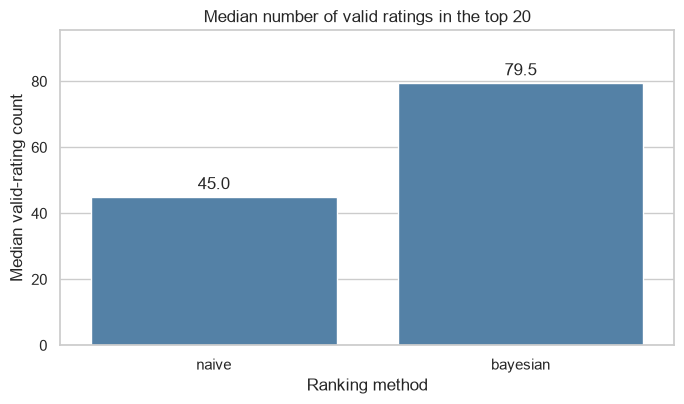

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.2))
sns.barplot(
    data=top_20_rating_evidence,
    x="ranking_method", y="median_rating_count",
    color="steelblue", ax=ax,
)
ax.set(
    title="Median number of valid ratings in the top 20",
    xlabel="Ranking method",
    ylabel="Median valid-rating count",
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f", padding=3)
ax.set_ylim(0, top_20_rating_evidence["median_rating_count"].max() * 1.2)
plt.tight_layout()
plt.show()

## 6. Finding 3: the smoothing strength matters

The parameter \(m\) is a modeling choice. Increasing it gives the overall mean \(C\) more influence. Every point below compares the corresponding weighted **top 20** against the same naive top 20.

### 6.1 Evaluate alternative smoothing strengths

In [13]:
presentation_sensitivity = ranking_evaluator.evaluate_smoothing_sensitivity(
    recipe_ranker=recipe_ranker,
    smoothing_strengths=[1, 5, 10, 20, 50, 100],
    top_k=PRESENTATION_TOP_K,
)
display(presentation_sensitivity.round(1))

,smoothing_strength,overlap_with_naive_percentage,median_top_k_rating_count
0,1,100.0,45.0
1,5,75.0,65.5
2,10,50.0,79.5
3,20,30.0,100.5
4,50,10.0,192.5
5,100,5.0,287.0


### 6.2 Visualize sensitivity

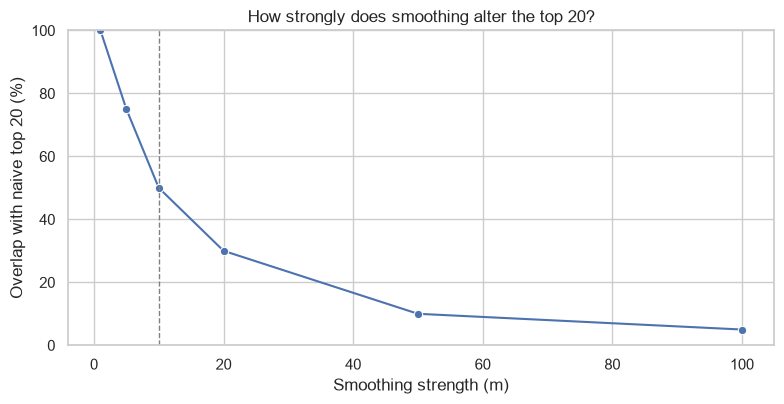

In [14]:
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.lineplot(
    data=presentation_sensitivity,
    x="smoothing_strength", y="overlap_with_naive_percentage",
    marker="o", ax=ax,
)
ax.axvline(SMOOTHING_STRENGTH, linestyle="--", color="gray", linewidth=1)
ax.set(
    title="How strongly does smoothing alter the top 20?",
    xlabel="Smoothing strength (m)",
    ylabel="Overlap with naive top 20 (%)",
    ylim=(0, 100),
)
plt.tight_layout()
plt.show()


## 7. Conclusion and limitations

### Key takeaways

With a smoothing strength of \(m=10\):

- **50% top-20 overlap:** Only 10 recipes appear in both leaderboards.
- **More rating evidence:** Median valid-rating counts increase from **45 to 79.5** among the top 20 recipes.
- **Parameter sensitivity:** Overlap with the naive top 20 decreases from **100% at \(m=1\)** to **5% at \(m=100\)**.

### Conclusion

Average ratings alone ignore the amount of evidence supporting each score. Bayesian-style shrinkage provides a transparent alternative that incorporates both the rating average and the number of ratings.

### Limitations

The smoothing strength is not optimized, user ratings may contain selection bias, and differences between rankings do not establish better future recommendations. The ranking is global and does not account for recipe categories.

**Final takeaway:** Considering rating counts changes which recipes rank highest, but ranking stability and recommendation quality are different questions.